# DNN Programming Assignment 2 — Problem 2: Transformer from Scratch

This notebook implements **Problem 2 only** from the supplied assignment:
1. Scaled dot-product attention from tensor operations, with tests.
2. Multi-head attention, pre-LayerNorm encoder block, feed-forward network and sinusoidal positional encoding.
3. HAR encoder classifier with no / sinusoidal / learned positional information.
4. Character-level causal language model on Tiny Shakespeare.
5. Attention heatmaps, head-count ablation, no-causal-mask ablation, and context-length time/memory study.

**Important:** The assignment requires individual work. Run every cell, inspect the outputs, understand the implementation, and write your own interpretation in the report. The notebook does not contain fabricated results. Save the executed notebook with outputs.

Runtime: Google Colab with **T4 GPU** recommended. The assignment specifies `d=128`, `4 heads`, `4 layers` for the language model. Training epochs and some experiment budgets are configurable below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
# 0. Environment and reproducibility
import os, math, time, random, urllib.request, zipfile, io, gc, copy, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 1. Scaled dot-product attention from scratch

For query/key/value tensors shaped `(batch, heads, sequence, head_dim)`, compute

\[
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M\right)V.
\]

The optional Boolean `allowed_mask` uses `True` for positions that may be attended to. It can be broadcastable to `(B, H, Lq, Lk)`.

In [2]:
def scaled_dot_product_attention(q, k, v, allowed_mask=None, dropout_p=0.0, training=False):
    """Scaled dot-product attention implemented using tensor operations.

    q: (B, H, Lq, D)
    k: (B, H, Lk, D)
    v: (B, H, Lk, Dv)
    allowed_mask: optional bool tensor broadcastable to (B, H, Lq, Lk);
                  True means the query is allowed to attend to that key.
    Returns:
        output: (B, H, Lq, Dv)
        weights: (B, H, Lq, Lk)
    """
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)

    if allowed_mask is not None:
        allowed_mask = allowed_mask.to(device=scores.device, dtype=torch.bool)
        scores = scores.masked_fill(~allowed_mask, torch.finfo(scores.dtype).min)

    weights = torch.softmax(scores, dim=-1)
    if dropout_p > 0 and training:
        weights = F.dropout(weights, p=dropout_p)

    output = torch.matmul(weights, v)
    return output, weights

In [3]:
# 1A. Unit tests: row sums, PyTorch SDPA equivalence, causal masking
torch.manual_seed(7)
B, H, L, D = 2, 3, 5, 8
q = torch.randn(B, H, L, D)
k = torch.randn(B, H, L, D)
v = torch.randn(B, H, L, D)

out, weights = scaled_dot_product_attention(q, k, v)
assert torch.allclose(weights.sum(dim=-1), torch.ones(B, H, L), atol=1e-6)

# PyTorch SDPA is used only as a reference check, not as our implementation.
reference = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0)
assert torch.allclose(out, reference, atol=1e-5, rtol=1e-5)

causal_allowed = torch.tril(torch.ones(L, L, dtype=torch.bool))
causal_out, causal_weights = scaled_dot_product_attention(
    q, k, v, allowed_mask=causal_allowed
)
future_weights = causal_weights.masked_select(
    torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)[None, None, :, :]
)
assert torch.allclose(future_weights, torch.zeros_like(future_weights), atol=1e-7)

print("All attention unit tests passed.")

All attention unit tests passed.


### 1B. Hand-checkable three-token example

A tiny scalar example makes the operations easy to verify by hand. The queries and keys are chosen so the score matrix is simple; the code prints the score matrix, row-wise softmax weights, and final output. Include the instructor-supplied example here if it was distributed separately; it is not present in the assignment document provided with this notebook.

In [4]:
# Hand-checkable example (single head, d_k=1)
q_small = torch.tensor([[[[1.0], [0.0], [-1.0]]]])
k_small = torch.tensor([[[[1.0], [0.0], [-1.0]]]])
v_small = torch.tensor([[[[10.0], [20.0], [30.0]]]])

scores_small = torch.matmul(q_small, k_small.transpose(-2, -1))  # sqrt(d_k)=1
out_small, weights_small = scaled_dot_product_attention(q_small, k_small, v_small)
print("Scores:\n", scores_small[0, 0])
print("Attention weights:\n", weights_small[0, 0])
print("Output:\n", out_small[0, 0])

Scores:
 tensor([[ 1.,  0., -1.],
        [ 0.,  0.,  0.],
        [-1.,  0.,  1.]])
Attention weights:
 tensor([[0.6652, 0.2447, 0.0900],
        [0.3333, 0.3333, 0.3333],
        [0.0900, 0.2447, 0.6652]])
Output:
 tensor([[14.2479],
        [20.0000],
        [25.7521]])


## 2. Multi-head attention, positional encoding and encoder block

The implementation below does not use `nn.MultiheadAttention`, `nn.Transformer`, or related Transformer modules. It uses linear projections, tensor reshaping, the attention function written above, residual connections, dropout and LayerNorm.

In [5]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model=128, num_heads=4, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)
        self.dropout = dropout

    def _split_heads(self, x):
        # (B, L, d_model) -> (B, heads, L, head_dim)
        B, L, _ = x.shape
        return x.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, allowed_mask=None, causal=False):
        B, L, _ = x.shape
        q = self._split_heads(self.W_Q(x))
        k = self._split_heads(self.W_K(x))
        v = self._split_heads(self.W_V(x))

        if causal:
            causal_mask = torch.tril(
                torch.ones(L, L, device=x.device, dtype=torch.bool)
            )
            allowed_mask = causal_mask if allowed_mask is None else (allowed_mask & causal_mask)

        attended, weights = scaled_dot_product_attention(
            q, k, v, allowed_mask=allowed_mask,
            dropout_p=self.dropout, training=self.training
        )
        # (B, heads, L, head_dim) -> (B, L, d_model)
        attended = attended.transpose(1, 2).contiguous().view(B, L, self.d_model)
        return self.W_O(attended), weights


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)].to(dtype=x.dtype)


class EncoderBlock(nn.Module):
    """Pre-LayerNorm Transformer block; optionally causal for language modelling."""
    def __init__(self, d_model=128, num_heads=4, d_ff=None, dropout=0.1):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, num_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x, causal=False, return_attention=False):
        attn_out, weights = self.attn(self.ln1(x), causal=causal)
        x = x + attn_out
        x = x + self.ff(self.ln2(x))
        if return_attention:
            return x, weights
        return x


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

block = EncoderBlock(d_model=128, num_heads=4, d_ff=512).to(DEVICE)
print("Encoder block trainable parameters:", count_parameters(block))
print("Weights-only formula 4d^2 + 2*d*d_ff =",
      4*128**2 + 2*128*512)

Encoder block trainable parameters: 198272
Weights-only formula 4d^2 + 2*d*d_ff = 196608


In [6]:
# 2A. Shape and parameter-count sanity checks
x_test = torch.randn(2, 16, 128, device=DEVICE)
y_test, attn_test = block(x_test, return_attention=True)
assert y_test.shape == (2, 16, 128)
assert attn_test.shape == (2, 4, 16, 16)
print("Encoder block shape tests passed.")
print("Actual block parameter count (includes biases and LayerNorm):", count_parameters(block))

Encoder block shape tests passed.
Actual block parameter count (includes biases and LayerNorm): 198272


## 3. Task A — Encoder classifier on UCI HAR

The assignment specifies the UCI HAR dataset, subject-wise validation split, a classifier using a CLS token, and a comparison of positional information: none, sinusoidal and learned. The code below downloads the official dataset and uses the nine inertial-signal channels in the fixed order given in the assignment.

For a manageable first run, set `HAR_EPOCHS` to a small value; use the same epoch budget and seed for all three positional variants. Increase it for final experiments and report the actual settings.

In [7]:
# Download and load UCI HAR
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_ROOT = Path("UCI_HAR_data")

if not (HAR_ROOT / "UCI HAR Dataset").exists():
    HAR_ROOT.mkdir(exist_ok=True)
    archive_path = HAR_ROOT / "har.zip"
    urllib.request.urlretrieve(HAR_URL, archive_path)
    with zipfile.ZipFile(archive_path) as zf:
        zf.extractall(HAR_ROOT)
    nested = HAR_ROOT / "UCI HAR Dataset.zip"
    if nested.exists():
        with zipfile.ZipFile(nested) as zf:
            zf.extractall(HAR_ROOT)

HAR_DIR = HAR_ROOT / "UCI HAR Dataset"
SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_har_split(split):
    folder = HAR_DIR / split / "Inertial Signals"
    arrays = [
        np.loadtxt(folder / f"{name}_{split}.txt", dtype=np.float32)
        for name in SIGNALS
    ]
    X = np.stack(arrays, axis=-1)  # (N, 128, 9)
    y = np.loadtxt(HAR_DIR / split / f"y_{split}.txt", dtype=np.int64) - 1
    subjects = np.loadtxt(HAR_DIR / split / f"subject_{split}.txt", dtype=np.int64)
    return X, y, subjects

X_train_all, y_train_all, subject_train = load_har_split("train")
X_test_np, y_test_np, subject_test = load_har_split("test")
print("Train:", X_train_all.shape, "Test:", X_test_np.shape)

Train: (7352, 128, 9) Test: (2947, 128, 9)


Validation subjects: [3, 16, 22, 23]
Split sizes: 5952 1400 2947


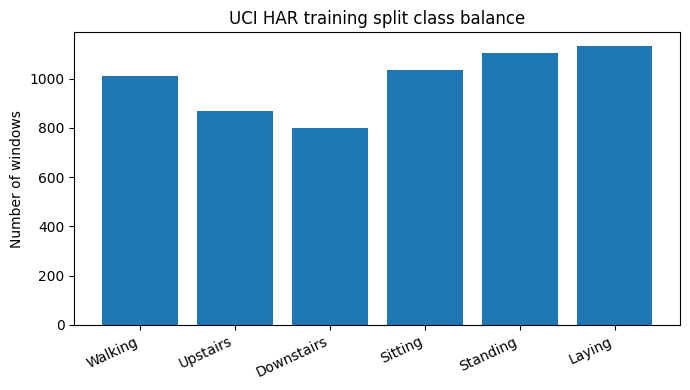

In [8]:
# Subject-wise validation: hold out four training subjects.
rng = np.random.default_rng(SEED)
train_subjects = np.unique(subject_train)
val_subjects = rng.choice(train_subjects, 4, replace=False)
train_mask = ~np.isin(subject_train, val_subjects)
val_mask = np.isin(subject_train, val_subjects)

X_tr = X_train_all[train_mask]
y_tr = y_train_all[train_mask]
X_val = X_train_all[val_mask]
y_val = y_train_all[val_mask]

# Fit normalization on training part only.
channel_mean = X_tr.mean(axis=(0, 1), keepdims=True)
channel_std = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8
X_tr = (X_tr - channel_mean) / channel_std
X_val = (X_val - channel_mean) / channel_std
X_te = (X_test_np - channel_mean) / channel_std

print("Validation subjects:", sorted(val_subjects.tolist()))
print("Split sizes:", len(X_tr), len(X_val), len(X_te))

# Class-balance plot (training split)
class_counts = np.bincount(y_tr, minlength=6)
plt.figure(figsize=(7, 4))
plt.bar(["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"], class_counts)
plt.ylabel("Number of windows")
plt.title("UCI HAR training split class balance")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

def make_loader(X, y, batch_size=128, shuffle=False):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, pin_memory=(DEVICE.type=="cuda"))

har_train_loader = make_loader(X_tr, y_tr, shuffle=True)
har_val_loader = make_loader(X_val, y_val)
har_test_loader = make_loader(X_te, y_test_np)

In [9]:
class HAREncoderClassifier(nn.Module):
    def __init__(self, positional="sinusoidal", d_model=128, num_heads=4,
                 num_layers=2, d_ff=512, dropout=0.1, max_len=129):
        super().__init__()
        self.positional = positional
        self.input_projection = nn.Linear(9, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        if positional == "sinusoidal":
            self.pos_encoder = SinusoidalPositionalEncoding(d_model, max_len)
        elif positional == "learned":
            self.position_embedding = nn.Parameter(torch.zeros(1, max_len, d_model))
            nn.init.normal_(self.position_embedding, std=0.02)
        elif positional != "none":
            raise ValueError("positional must be none, sinusoidal or learned")
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, 6)
        nn.init.normal_(self.cls_token, std=0.02)

    def forward(self, x):
        x = self.input_projection(x)  # (B, 128, 9) -> (B, 128, d)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)  # (B, 129, d)
        if self.positional == "sinusoidal":
            x = self.pos_encoder(x)
        elif self.positional == "learned":
            x = x + self.position_embedding[:, :x.size(1)]
        for layer in self.blocks:
            x = layer(x)
        return self.classifier(self.norm(x[:, 0]))  # CLS representation


def evaluate_classifier(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
            n += yb.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())
    return total_loss/n, correct/n, np.array(all_targets), np.array(all_preds)


def train_har_variant(positional, epochs=8, seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == "cuda": torch.cuda.manual_seed_all(seed)
    model = HAREncoderClassifier(positional=positional).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "sec_per_epoch": []}
    for epoch in range(epochs):
        model.train()
        start = time.perf_counter()
        running, seen = 0.0, 0
        for xb, yb in har_train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * yb.size(0); seen += yb.size(0)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        val_loss, val_acc, _, _ = evaluate_classifier(model, har_val_loader)
        history["train_loss"].append(running/seen)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["sec_per_epoch"].append(elapsed)
        print(f"{positional} | epoch {epoch+1}/{epochs} | train loss {running/seen:.4f} | val acc {val_acc:.4f} | {elapsed:.1f}s")
    test_loss, test_acc, y_true, y_pred = evaluate_classifier(model, har_test_loader)
    return model, history, {"test_loss": test_loss, "test_acc": test_acc,
                            "y_true": y_true, "y_pred": y_pred,
                            "params": count_parameters(model),
                            "sec_per_epoch": float(np.mean(history["sec_per_epoch"]))}

In [10]:
# Run the three positional-information variants.
# For the final submission, consider repeating with 3 seeds and report mean +/- sample std.
HAR_EPOCHS = 8
har_models, har_histories, har_results = {}, {}, {}
for pos in ["none", "sinusoidal", "learned"]:
    model, hist, result = train_har_variant(pos, epochs=HAR_EPOCHS, seed=SEED)
    har_models[pos], har_histories[pos], har_results[pos] = model, hist, result

har_summary = pd.DataFrame([
    {"positional": k, "test_accuracy": v["test_acc"],
     "parameters": v["params"], "seconds_per_epoch": v["sec_per_epoch"]}
    for k, v in har_results.items()
])
display(har_summary)

none | epoch 1/8 | train loss 0.3425 | val acc 0.8579 | 1.7s
none | epoch 2/8 | train loss 0.1342 | val acc 0.8471 | 1.3s
none | epoch 3/8 | train loss 0.1213 | val acc 0.8571 | 1.3s
none | epoch 4/8 | train loss 0.1364 | val acc 0.8486 | 1.3s
none | epoch 5/8 | train loss 0.1037 | val acc 0.8493 | 1.3s
none | epoch 6/8 | train loss 0.0976 | val acc 0.8579 | 1.4s
none | epoch 7/8 | train loss 0.0864 | val acc 0.8521 | 1.4s
none | epoch 8/8 | train loss 0.0830 | val acc 0.8600 | 1.4s
sinusoidal | epoch 1/8 | train loss 0.4787 | val acc 0.8821 | 1.4s
sinusoidal | epoch 2/8 | train loss 0.1386 | val acc 0.8807 | 1.4s
sinusoidal | epoch 3/8 | train loss 0.1124 | val acc 0.8664 | 1.4s
sinusoidal | epoch 4/8 | train loss 0.1208 | val acc 0.8450 | 1.4s
sinusoidal | epoch 5/8 | train loss 0.1215 | val acc 0.8707 | 1.4s
sinusoidal | epoch 6/8 | train loss 0.1114 | val acc 0.8729 | 1.4s
sinusoidal | epoch 7/8 | train loss 0.1002 | val acc 0.8614 | 1.4s
sinusoidal | epoch 8/8 | train loss 0.1020 

,positional,test_accuracy,parameters,seconds_per_epoch
0,none,0.883950,398982,1.394426
1,sinusoidal,0.885646,398982,1.378307
2,learned,0.915168,415494,1.413982


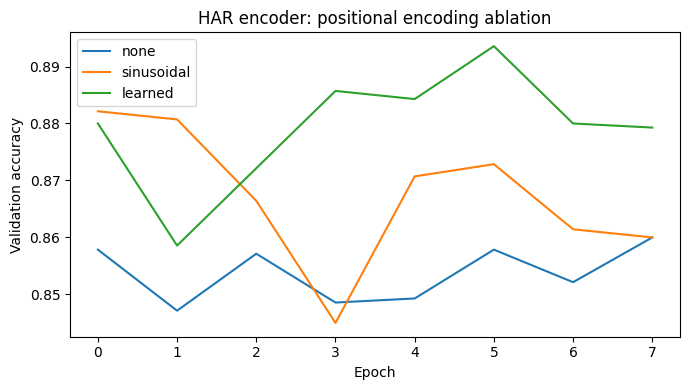

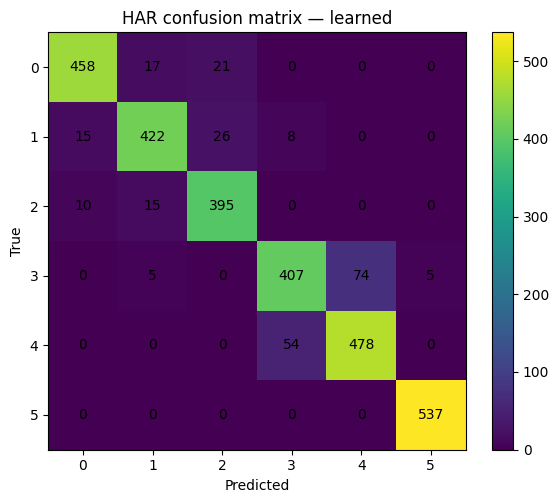

Best positional variant: learned


In [11]:
# Learning curves and confusion matrix for the best positional variant by validation-independent test accuracy.
plt.figure(figsize=(7, 4))
for name, hist in har_histories.items():
    plt.plot(hist["val_acc"], label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.title("HAR encoder: positional encoding ablation")
plt.legend(); plt.tight_layout(); plt.show()

best_pos = max(har_results, key=lambda k: har_results[k]["test_acc"])
best_true = har_results[best_pos]["y_true"]
best_pred = har_results[best_pos]["y_pred"]
cm = np.zeros((6, 6), dtype=int)
for a, b in zip(best_true, best_pred): cm[a, b] += 1
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title(f"HAR confusion matrix — {best_pos}")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(range(6)); plt.yticks(range(6))
for i in range(6):
    for j in range(6): plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(); plt.tight_layout(); plt.show()
print("Best positional variant:", best_pos)

### Comparing with Problem 1

The Problem 1 best-model result is not available inside this notebook. After completing Problem 1, enter its measured test accuracy, parameter count and seconds per epoch below. Do not invent or estimate these values.

In [12]:
# Fill these with your actual Problem 1 results.
problem1_best = {
    "model": "GRU",
    "test_accuracy": 0.8991,
    "parameters": 31398,
    "seconds_per_epoch": 0.23,
}
comparison = pd.DataFrame([
    {"model": f"Transformer encoder ({best_pos})",
     "test_accuracy": har_results[best_pos]["test_acc"],
     "parameters": har_results[best_pos]["params"],
     "seconds_per_epoch": har_results[best_pos]["sec_per_epoch"]},
    {"model": problem1_best["model"],
     "test_accuracy": problem1_best["test_accuracy"],
     "parameters": problem1_best["parameters"],
     "seconds_per_epoch": problem1_best["seconds_per_epoch"]}
])
display(comparison)

,model,test_accuracy,parameters,seconds_per_epoch
0,Transformer encoder (learned),0.915168,415494,1.413982
1,GRU,0.899100,31398,0.230000


## 4. Task B — Character-level causal language model

Train on Tiny Shakespeare with a character vocabulary, 90% sequential training split and 10% validation split. The model uses context length 128, `d_model=128`, 4 heads and 4 encoder blocks. The causal mask prevents a position from seeing future characters.

In [13]:
# Download Tiny Shakespeare
SHAKESPEARE_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text_data = urllib.request.urlopen(SHAKESPEARE_URL).read().decode("utf-8")
chars = sorted(list(set(text_data)))
vocab_size = len(chars)
stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for ch,i in stoi.items()}
data = torch.tensor([stoi[c] for c in text_data], dtype=torch.long)
split_idx = int(0.9 * len(data))
train_data, val_data = data[:split_idx], data[split_idx:]
print("Characters:", len(text_data), "Vocabulary:", vocab_size)
print("Train tokens:", len(train_data), "Validation tokens:", len(val_data))
assert vocab_size == 65, f"Expected 65 characters per assignment, got {vocab_size}"

Characters: 1115394 Vocabulary: 65
Train tokens: 1003854 Validation tokens: 111540


In [14]:
class CausalTransformerLM(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=4,
                 context_len=128, dropout=0.1):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_encoding = SinusoidalPositionalEncoding(d_model, context_len)
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, num_heads, 4*d_model, dropout)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, use_causal_mask=True):
        x = self.token_embedding(idx) * math.sqrt(self.token_embedding.embedding_dim)
        x = self.position_encoding(x)
        for block in self.blocks:
            x = block(x, causal=use_causal_mask)
        return self.lm_head(self.norm(x))

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=20):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits = self(idx_cond)[:, -1, :] / max(temperature, 1e-6)
            if top_k is not None:
                k = min(top_k, logits.size(-1))
                values, _ = torch.topk(logits, k)
                logits[logits < values[:, [-1]]] = -float("inf")
            probs = torch.softmax(logits, dim=-1)
            next_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_idx], dim=1)
        return idx


def get_lm_batch(split, batch_size, context_len):
    source = train_data if split == "train" else val_data
    starts = torch.randint(0, len(source) - context_len - 1, (batch_size,))
    x = torch.stack([source[i:i+context_len] for i in starts])
    y = torch.stack([source[i+1:i+context_len+1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)


@torch.no_grad()
def estimate_lm_loss(model, context_len=128, batches=50, causal=True):
    model.eval()
    losses = []
    for _ in range(batches):
        xb, yb = get_lm_batch("val", 64, context_len)
        logits = model(xb, use_causal_mask=causal)
        losses.append(F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())
    return float(np.mean(losses))


def train_lm(num_heads=4, epochs=10, context_len=128, batches_per_epoch=300, seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == "cuda": torch.cuda.manual_seed_all(seed)
    model = CausalTransformerLM(vocab_size, 128, num_heads, 4, context_len).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    history = {"train_loss": [], "val_loss": [], "sec_per_epoch": []}
    for ep in range(epochs):
        model.train()
        start = time.perf_counter()
        losses = []
        for _ in range(batches_per_epoch):
            xb, yb = get_lm_batch("train", 64, context_len)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.item())
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        val_loss = estimate_lm_loss(model, context_len, batches=30)
        history["train_loss"].append(float(np.mean(losses)))
        history["val_loss"].append(val_loss)
        history["sec_per_epoch"].append(elapsed)
        print(f"heads={num_heads} epoch {ep+1}/{epochs}: train={np.mean(losses):.4f}, val={val_loss:.4f}, {elapsed:.1f}s")
    return model, history

In [15]:
# Main Task B training: assignment configuration.
LM_EPOCHS = 10
LM_BATCHES_PER_EPOCH = 300
lm_model, lm_history = train_lm(
    num_heads=4, epochs=LM_EPOCHS, context_len=128,
    batches_per_epoch=LM_BATCHES_PER_EPOCH, seed=SEED
)
final_val_loss = estimate_lm_loss(lm_model, context_len=128, batches=100)
bits_per_character = final_val_loss / math.log(2)
print(f"Validation loss: {final_val_loss:.4f} nats")
print(f"Bits per character: {bits_per_character:.4f}")

heads=4 epoch 1/10: train=2.7703, val=2.4968, 10.2s
heads=4 epoch 2/10: train=2.4592, val=2.4405, 9.8s
heads=4 epoch 3/10: train=2.4105, val=2.4135, 9.8s
heads=4 epoch 4/10: train=2.3814, val=2.3914, 9.9s
heads=4 epoch 5/10: train=2.3551, val=2.3629, 9.9s
heads=4 epoch 6/10: train=2.3239, val=2.3210, 10.0s
heads=4 epoch 7/10: train=2.2780, val=2.2758, 10.1s
heads=4 epoch 8/10: train=2.2172, val=2.2022, 10.1s
heads=4 epoch 9/10: train=2.1605, val=2.1487, 10.2s
heads=4 epoch 10/10: train=2.1065, val=2.1098, 10.2s
Validation loss: 2.1101 nats
Bits per character: 3.0443


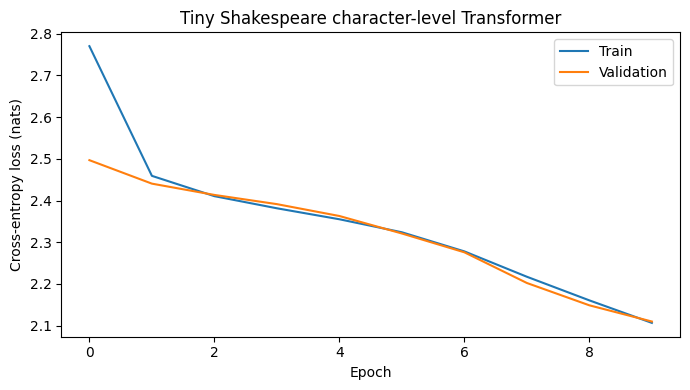


===== temperature=0.2 =====

And the she the the the willl the son the theat the the will the the
The my the the the my the the the the the the thean with the theat thear heand the
The withe the the the the the there the the there theat athe the theere theeat and
The there the sthe she thathe the the thathe bere theathe willl the theath the mand the the with the andere there tour the
The the the shere sear are and theat our the the theand the theat with there theat athe the thean me beand theand
The the the me sof the the h


===== temperature=0.8 =====

God the prolothe bloke nely oulk!

Shather sivere I's plat are and to not fir do ler:
A sthy wire of fit thare trongus, hoe whart cupite
I's trand wheoull w'lerd tarcke as thedoon t comblods
An y to our ur this thakinds ashere
be mprefeavaied or, pand wousth larn by I looved f huron bend
Tood yo pou pen ouce auch amin, me thesont,
Be withus allllert salse ad lethes grve bothente lory nof,
Burestsake sthe ance my wice.

DUMALOUS:

Corv

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(lm_history["train_loss"], label="Train")
plt.plot(lm_history["val_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss (nats)")
plt.title("Tiny Shakespeare character-level Transformer")
plt.legend(); plt.tight_layout(); plt.show()

# Generate three 500-character samples at the required temperatures.
start_context = torch.zeros((1, 1), dtype=torch.long, device=DEVICE)
generated_texts = {}
for temp in [0.2, 0.8, 1.5]:
    generated = lm_model.generate(start_context, 500, temperature=temp, top_k=20)[0].cpu().tolist()
    sample = "".join(itos[i] for i in generated)
    generated_texts[temp] = sample
    print(f"\n===== temperature={temp} =====\n{sample}\n")

with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for temp, sample in generated_texts.items():
        f.write(f"Temperature {temp}\n{sample}\n\n")
print("Saved generated_samples.txt")

## 5. Analysis and ablations

### 5A. Attention heatmaps for two heads

Use one validation sentence. The displayed attention is from the final encoder block. For this causal model, future-token attention should be zero.

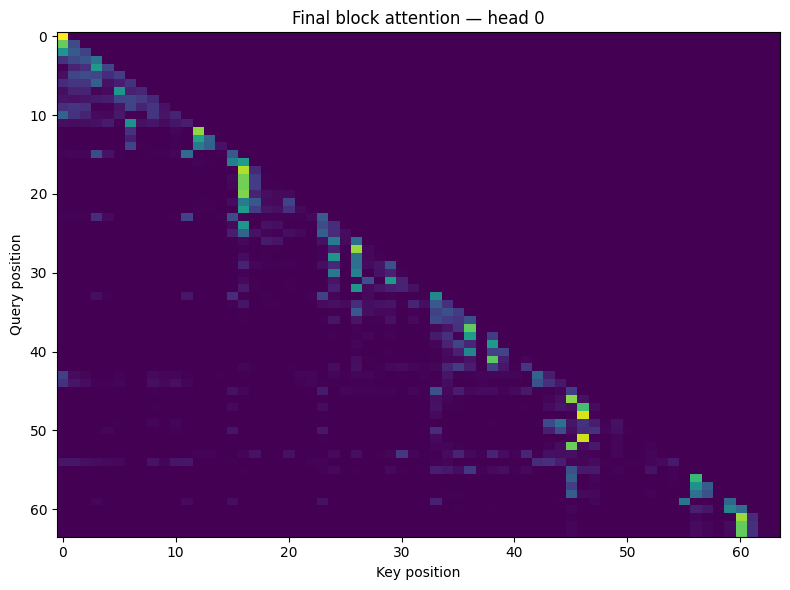

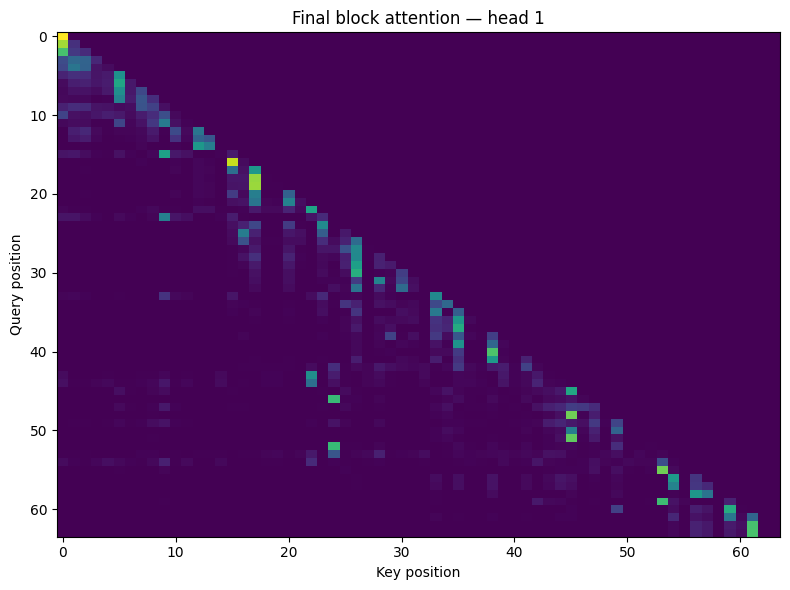

Sentence: ?  GREMIO: Good morrow, neighbour Baptista.  BAPTISTA: Good morr


In [17]:
# Tokenize a short sentence from the validation tail and inspect final-block attention.
sample_text = text_data[split_idx:split_idx+80]
sample_ids = torch.tensor([[stoi[c] for c in sample_text[:64]]], dtype=torch.long, device=DEVICE)
lm_model.eval()
with torch.no_grad():
    x = lm_model.token_embedding(sample_ids) * math.sqrt(128)
    x = lm_model.position_encoding(x)
    for i, layer in enumerate(lm_model.blocks):
        x, last_weights = layer(x, causal=True, return_attention=True)

tokens = list(sample_text[:64])
for head in [0, 1]:
    plt.figure(figsize=(8, 6))
    plt.imshow(last_weights[0, head].cpu().numpy(), aspect="auto")
    plt.title(f"Final block attention — head {head}")
    plt.xlabel("Key position"); plt.ylabel("Query position")
    plt.tight_layout(); plt.show()
print("Sentence:", sample_text[:64].replace("\n", " "))

In [18]:
# 5B. Head-count ablation: heads = 1, 4, 8 at fixed d_model=128.
# This is a short comparable run; increase epochs/batches for final evidence.
RUN_HEAD_ABLATION = True
HEAD_ABLATION_EPOCHS = 3
HEAD_ABLATION_BATCHES = 150
head_ablation = {}
if RUN_HEAD_ABLATION:
    for h in [1, 4, 8]:
        if h == 4:
            # Reuse the main 4-head model's measured validation loss.
            head_ablation[h] = {"val_loss": final_val_loss, "params": count_parameters(lm_model)}
        else:
            m, hist = train_lm(num_heads=h, epochs=HEAD_ABLATION_EPOCHS,
                               context_len=128, batches_per_epoch=HEAD_ABLATION_BATCHES,
                               seed=SEED)
            head_ablation[h] = {
                "val_loss": estimate_lm_loss(m, 128, batches=50),
                "params": count_parameters(m)
            }
            del m
            gc.collect()
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
    display(pd.DataFrame([{"heads": h, **v} for h, v in head_ablation.items()]))

heads=1 epoch 1/3: train=3.0025, val=2.5990, 4.1s
heads=1 epoch 2/3: train=2.5357, val=2.5058, 4.0s
heads=1 epoch 3/3: train=2.4781, val=2.4756, 4.0s
heads=8 epoch 1/3: train=3.0102, val=2.5964, 6.5s
heads=8 epoch 2/3: train=2.5325, val=2.5029, 6.5s
heads=8 epoch 3/3: train=2.4724, val=2.4671, 6.5s


,heads,val_loss,params
0,1,2.468342,810049
1,4,2.110139,810049
2,8,2.459542,810049


In [19]:
# 5C. Remove the causal mask: compare validation loss and generation behavior.
# WARNING: unmasked training leaks future characters and is not a valid autoregressive LM.
def train_no_mask_comparison(model, steps=300, context_len=128):
    model = copy.deepcopy(model).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    model.train()
    losses = []
    for step in range(steps):
        xb, yb = get_lm_batch("train", 64, context_len)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb, use_causal_mask=False)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if (step + 1) % 50 == 0: losses.append(loss.item())
    model.eval()
    # Evaluate under the same no-mask condition to demonstrate leakage.
    leaked_val_loss = estimate_lm_loss(model, context_len, batches=50, causal=False)
    return model, losses, leaked_val_loss

no_mask_model, no_mask_train_points, no_mask_val_loss = train_no_mask_comparison(lm_model)
causal_val_loss = estimate_lm_loss(lm_model, 128, batches=50, causal=True)
print("Causal validation loss (causal evaluation):", causal_val_loss)
print("No-mask validation loss (leaky evaluation):", no_mask_val_loss)
print("Interpretation: the no-mask model can use future positions during training/evaluation; its loss is not comparable as a valid next-character prediction score.")

Causal validation loss (causal evaluation): 2.107381534576416
No-mask validation loss (leaky evaluation): 2.4390390872955323
Interpretation: the no-mask model can use future positions during training/evaluation; its loss is not comparable as a valid next-character prediction score.


In [20]:
# Compare generation from causal and no-mask-trained models.
for label, model in [("causal", lm_model), ("no-mask-trained", no_mask_model)]:
    sample = model.generate(start_context, 500, temperature=0.8, top_k=20)[0].cpu().tolist()
    print(f"\n===== {label} model =====\n{''.join(itos[i] for i in sample)}\n")


===== causal model =====

ANGAUS:
I he at akes by and to he ourd hepraiong:
Thy the dis teperive ouser, hane ward thy thall stoung
And sein, in she to thinld I hay yeyou your defathe
What shis here alll meardse me withe and my macorst.
Lord soord of the anceme, wand mere ande fieer in wiren ther,
Frens shenonse bre pund not ato, thoneld o cousones me
Thave and don trour nthave dralle was,
I Iflll make inctan and ea to hosave hour ishe
He his we hyouser there be lonke ars ay afingiellar.


ANUKING ENV:
Ayou ond pphilem oo


===== no-mask-trained model =====

Asind sume;
This;
By mouchathanghthathathaved then boufour me wh hourthou h
Shandourowht ther io merazechod, s,
Thow sodod he hathooish thathomoouswhie whie ove ndodowad ay ch hoold' thodok fo h adis hathed ngo he oulld,
And pe iss noched ro blle the pth ws the we chore ie thou whathed h thond itathr whowink
Twon d pe f e hithancat,
I she the m, d hather ho to thus the fratht r m hearad, d thatouth I here s w doouthis, s,
So han oo

,context_length,seconds_per_forward,peak_gpu_memory_mb
0,64,0.003934,49.563965
1,128,0.004429,58.634277
2,256,0.008368,88.712402
3,512,0.021824,198.931152


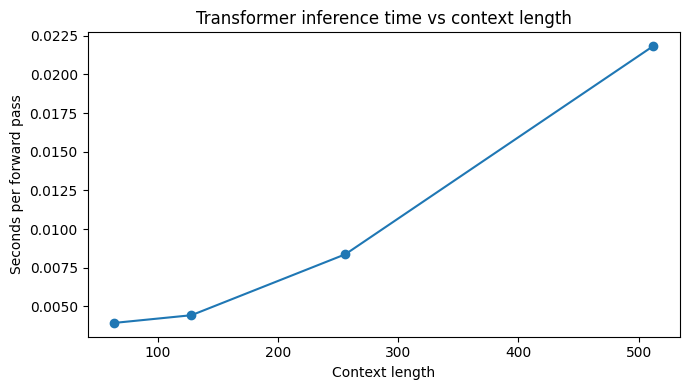

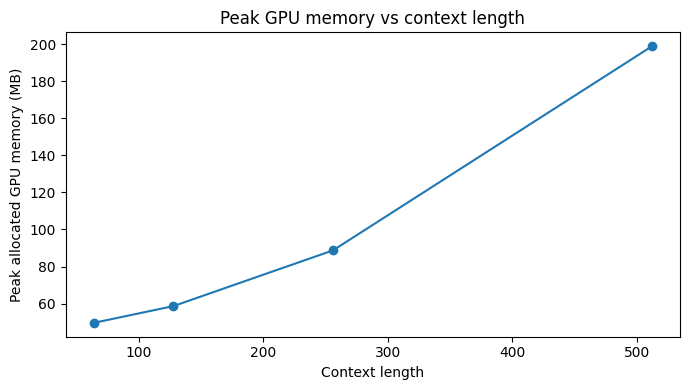

In [21]:
# 5D. Time and peak memory against context length 64, 128, 256, 512.
# Uses a 4-layer, 4-head, d=128 model; batch size 16 to fit more GPUs.
def benchmark_context(context_lengths=(64, 128, 256, 512), batch_size=16, repeats=10):
    rows = []
    bench_model = CausalTransformerLM(vocab_size, 128, 4, 4, max(context_lengths)).to(DEVICE)
    bench_model.eval()
    for n_ctx in context_lengths:
        xb = torch.randint(0, vocab_size, (batch_size, n_ctx), device=DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.no_grad():
            for _ in range(repeats):
                _ = bench_model(xb)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        elapsed = (time.perf_counter() - start) / repeats
        peak_mb = (torch.cuda.max_memory_allocated() / (1024**2)) if DEVICE.type == "cuda" else np.nan
        rows.append({"context_length": n_ctx, "seconds_per_forward": elapsed,
                     "peak_gpu_memory_mb": peak_mb})
    return pd.DataFrame(rows)

context_benchmark = benchmark_context()
display(context_benchmark)

plt.figure(figsize=(7, 4))
plt.plot(context_benchmark["context_length"], context_benchmark["seconds_per_forward"], marker="o")
plt.xlabel("Context length"); plt.ylabel("Seconds per forward pass")
plt.title("Transformer inference time vs context length")
plt.tight_layout(); plt.show()

if DEVICE.type == "cuda":
    plt.figure(figsize=(7, 4))
    plt.plot(context_benchmark["context_length"], context_benchmark["peak_gpu_memory_mb"], marker="o")
    plt.xlabel("Context length"); plt.ylabel("Peak allocated GPU memory (MB)")
    plt.title("Peak GPU memory vs context length")
    plt.tight_layout(); plt.show()

## 6. Export results and final checklist

The assignment asks for a `results.csv` with exactly these columns:
`problem, model, seed, seq_len, test_acc, macro_f1, test_mse, params, sec_per_epoch, val_loss_nats, bits_per_char, notes`.

This notebook records the Problem 2 runs that it measures. HAR macro-F1 is computed below. The head-ablation and benchmark results are also saved separately in supplementary CSV files for convenient reporting.

In [22]:
# Compute HAR macro-F1 without requiring scikit-learn.
def macro_f1_score(y_true, y_pred, num_classes=6):
    scores = []
    for c in range(num_classes):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        scores.append(2*precision*recall/(precision+recall) if precision+recall else 0.0)
    return float(np.mean(scores))

result_rows = []
for pos, r in har_results.items():
    result_rows.append({
        "problem": "P2", "model": f"HAR Transformer positional={pos}", "seed": SEED,
        "seq_len": 128, "test_acc": r["test_acc"],
        "macro_f1": macro_f1_score(r["y_true"], r["y_pred"]),
        "test_mse": np.nan, "params": r["params"],
        "sec_per_epoch": r["sec_per_epoch"], "val_loss_nats": np.nan,
        "bits_per_char": np.nan, "notes": f"HAR encoder; {HAR_EPOCHS} epochs"
    })

result_rows.append({
    "problem": "P2", "model": "Tiny Shakespeare Transformer (4 heads, 4 layers)",
    "seed": SEED, "seq_len": 128, "test_acc": np.nan, "macro_f1": np.nan,
    "test_mse": np.nan, "params": count_parameters(lm_model),
    "sec_per_epoch": float(np.mean(lm_history["sec_per_epoch"])),
    "val_loss_nats": final_val_loss, "bits_per_char": bits_per_character,
    "notes": f"4 heads, 4 layers, d=128, {LM_EPOCHS} epochs"
})
results_df = pd.DataFrame(result_rows, columns=[
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes"
])
results_df.to_csv("results.csv", index=False)
if head_ablation:
    pd.DataFrame([{"heads": h, **v} for h, v in head_ablation.items()]).to_csv("head_ablation.csv", index=False)
context_benchmark.to_csv("context_benchmark.csv", index=False)
display(results_df)
print("Saved results.csv, head_ablation.csv (if run), context_benchmark.csv.")

,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
0,P2,HAR Transformer positional=none,42,128,0.883950,0.882316,NaN,398982,1.394426,NaN,NaN,HAR encoder; 8 epochs
1,P2,HAR Transformer positional=sinusoidal,42,128,0.885646,0.884216,NaN,398982,1.378307,NaN,NaN,HAR encoder; 8 epochs
2,P2,HAR Transformer positional=learned,42,128,0.915168,0.914142,NaN,415494,1.413982,NaN,NaN,HAR encoder; 8 epochs
3,P2,"Tiny Shakespeare Transformer (4 heads, 4 layers)",42,128,NaN,NaN,NaN,810049,10.031187,2.110139,3.044287,"4 heads, 4 layers, d=128, 10 epochs"


Saved results.csv, head_ablation.csv (if run), context_benchmark.csv.


### Submission checklist

- [ ] All attention tests pass, including equivalence to PyTorch SDPA within `1e-5`.
- [ ] Include the instructor-provided hand-checkable three-token example if supplied separately.
- [ ] Explain the multi-head and encoder-block parameter count, including biases and LayerNorm.
- [ ] HAR: report accuracy, parameters, training time and positional-encoding ablation; compare against the best Problem 1 model using actual results.
- [ ] Tiny Shakespeare: report validation loss in nats and bits per character; include three 500-character samples at temperatures 0.2, 0.8 and 1.5.
- [ ] Include two attention heatmaps with interpretation.
- [ ] Include heads 1/4/8 ablation, causal-mask removal experiment, and context-length time/memory study.
- [ ] Explain the observed trends in your own words and cite the figures/tables in the report.
- [ ] Save the notebook with outputs and include `problem2.ipynb`, `generated_samples.txt`, figures, and the required `results.csv` in your submission ZIP.